In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Load manufacturing datasets

production_lines = pd.read_csv("../Dataset/Production_Lines.csv")
machines = pd.read_csv("../Dataset/Machines.csv")
products = pd.read_csv("../Dataset/Products.csv")
production_orders = pd.read_csv("../Dataset/Production_Orders.csv")
production_records = pd.read_csv("../Dataset/Production_Records.csv")
quality_inspections = pd.read_csv("../Dataset/Quality_Inspections.csv")
downtime_logs = pd.read_csv("../Dataset/Downtime_Logs.csv")

print("All datasets loaded successfully!")


All datasets loaded successfully!


In [5]:

datasets = {
    "Production Lines": production_lines,
    "Machines": machines,
    "Products": products,
    "Production Orders": production_orders,
    "Production Records": production_records,
    "Quality Inspections": quality_inspections,
    "Downtime Logs": downtime_logs
}

for name, df in datasets.items():
    print(f"{name}: {df.shape[0]} rows, {df.shape[1]} columns")


Production Lines: 5 rows, 4 columns
Machines: 20 rows, 5 columns
Products: 15 rows, 4 columns
Production Orders: 1000 rows, 5 columns
Production Records: 5000 rows, 8 columns
Quality Inspections: 5000 rows, 6 columns
Downtime Logs: 1000 rows, 5 columns


In [7]:

# Inspect the production records dataset

print("First 5 records:")
display(production_records.head())

print("\nDataset Information:")
production_records.info()

print("\nStatistical Summary:")
display(production_records.describe())


First 5 records:


,Record_ID,Order_ID,Machine_ID,Shift_Name,Production_Date,Total_Units,Good_Units,Rejected_Units
0,1,5001,1014,Morning,2025-06-13,124,121,3
1,2,5001,1014,Evening,2025-06-13,116,107,9
2,3,5001,1015,Night,2025-06-13,104,95,9
3,4,5001,1015,Morning,2025-06-13,99,96,3
4,5,5001,1014,Evening,2025-06-13,120,113,7



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 8 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   Record_ID        5000 non-null   int64 
 1   Order_ID         5000 non-null   int64 
 2   Machine_ID       5000 non-null   int64 
 3   Shift_Name       5000 non-null   object
 4   Production_Date  5000 non-null   object
 5   Total_Units      5000 non-null   int64 
 6   Good_Units       5000 non-null   int64 
 7   Rejected_Units   5000 non-null   int64 
dtypes: int64(6), object(2)
memory usage: 312.6+ KB

Statistical Summary:


,Record_ID,Order_ID,Machine_ID,Total_Units,Good_Units,Rejected_Units
count,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000,5000.000000
mean,2500.500000,5500.500000,1010.404200,142.090800,134.234400,7.856400
std,1443.520003,288.703862,5.806717,36.211214,34.432975,4.270296
min,1.000000,5001.000000,1001.000000,57.000000,53.000000,1.000000
25%,1250.750000,5250.750000,1005.000000,112.000000,105.000000,4.000000
50%,2500.500000,5500.500000,1010.000000,142.000000,135.000000,7.000000
75%,3750.250000,5750.250000,1016.000000,172.000000,163.000000,11.000000
max,5000.000000,6000.000000,1020.000000,241.000000,228.000000,21.000000


In [9]:

# Check missing values in all datasets

for name, df in datasets.items():
    print(f"\n{name}")
    print(df.isnull().sum())



Production Lines
Line_ID               0
Line_Name             0
Location              0
Capacity_Per_Shift    0
dtype: int64

Machines
Machine_ID           0
Machine_Name         0
Line_ID              0
Machine_Type         0
Installation_Date    0
dtype: int64

Products
Product_ID                     0
Product_Name                   0
Product_Category               0
Standard_Cycle_Time_Seconds    0
dtype: int64

Production Orders
Order_ID            0
Product_ID          0
Line_ID             0
Order_Date          0
Planned_Quantity    0
dtype: int64

Production Records
Record_ID          0
Order_ID           0
Machine_ID         0
Shift_Name         0
Production_Date    0
Total_Units        0
Good_Units         0
Rejected_Units     0
dtype: int64

Quality Inspections
Inspection_ID         0
Order_ID              0
Inspection_Date       0
Inspected_Quantity    0
Defect_Quantity       0
Defect_Type           0
dtype: int64

Downtime Logs
Downtime_ID         0
Machine_ID          0


In [11]:

# Check duplicate records in all datasets

for name, df in datasets.items():
    duplicates = df.duplicated().sum()
    print(f"{name}: {duplicates} duplicate records")


Production Lines: 0 duplicate records
Machines: 0 duplicate records
Products: 0 duplicate records
Production Orders: 0 duplicate records
Production Records: 0 duplicate records
Quality Inspections: 0 duplicate records
Downtime Logs: 0 duplicate records


In [13]:

# Manufacturing KPI Analysis

total_production = production_records["Total_Units"].sum()
good_production = production_records["Good_Units"].sum()
rejected_production = production_records["Rejected_Units"].sum()

rejection_rate = (rejected_production / total_production) * 100
quality_rate = (good_production / total_production) * 100

print("MANUFACTURING KPI REPORT")
print("-------------------------")
print(f"Total Production: {total_production:,}")
print(f"Good Production: {good_production:,}")
print(f"Rejected Production: {rejected_production:,}")
print(f"Rejection Rate: {rejection_rate:.2f}%")
print(f"Quality Rate: {quality_rate:.2f}%")


MANUFACTURING KPI REPORT
-------------------------
Total Production: 710,454
Good Production: 671,172
Rejected Production: 39,282
Rejection Rate: 5.53%
Quality Rate: 94.47%


In [15]:

# Shift-wise Production Analysis

shift_analysis = production_records.groupby("Shift_Name").agg(
    Total_Production=("Total_Units", "sum"),
    Good_Production=("Good_Units", "sum"),
    Rejected_Units=("Rejected_Units", "sum")
).reset_index()

shift_analysis["Rejection_Rate"] = (
    shift_analysis["Rejected_Units"] /
    shift_analysis["Total_Production"] * 100
).round(2)

shift_analysis = shift_analysis.sort_values(
    by="Total_Production", ascending=False
)

display(shift_analysis)


,Shift_Name,Total_Production,Good_Production,Rejected_Units,Rejection_Rate
1,Morning,284480,268669,15811,5.56
0,Evening,283943,268264,15679,5.52
2,Night,142031,134239,7792,5.49


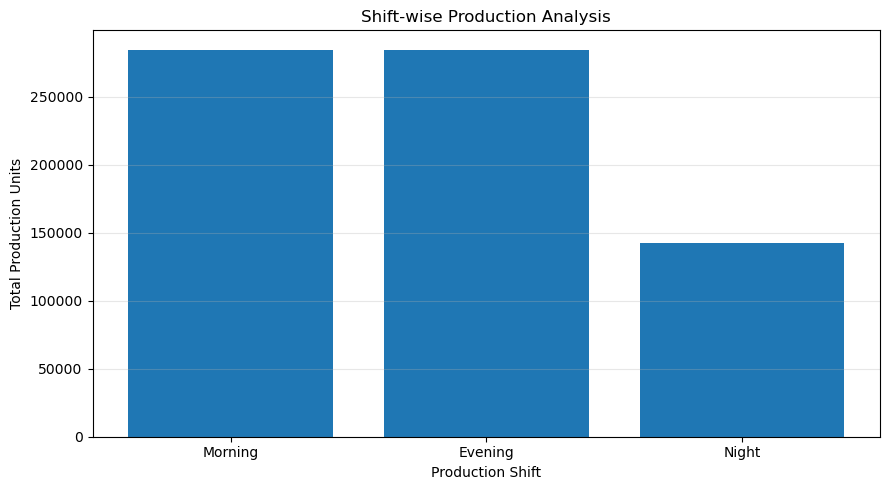

In [17]:

# Shift-wise Production Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    shift_analysis["Shift_Name"],
    shift_analysis["Total_Production"]
)

plt.title("Shift-wise Production Analysis")
plt.xlabel("Production Shift")
plt.ylabel("Total Production Units")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [19]:

# Machine-wise Rejection Analysis

machine_analysis = production_records.groupby("Machine_ID").agg(
    Total_Production=("Total_Units", "sum"),
    Good_Production=("Good_Units", "sum"),
    Rejected_Units=("Rejected_Units", "sum")
).reset_index()

machine_analysis["Rejection_Rate"] = (
    machine_analysis["Rejected_Units"] /
    machine_analysis["Total_Production"] * 100
).round(2)

machine_analysis = machine_analysis.sort_values(
    by="Rejection_Rate",
    ascending=False
)

display(machine_analysis)


,Machine_ID,Total_Production,Good_Production,Rejected_Units,Rejection_Rate
6,1007,40125,37798,2327,5.80
13,1014,32608,30729,1879,5.76
2,1003,33582,31654,1928,5.74
0,1001,37318,35179,2139,5.73
12,1013,31590,29782,1808,5.72
5,1006,36158,34107,2051,5.67
10,1011,37655,35530,2125,5.64
15,1016,36152,34140,2012,5.57
18,1019,37803,35697,2106,5.57
9,1010,38505,36377,2128,5.53


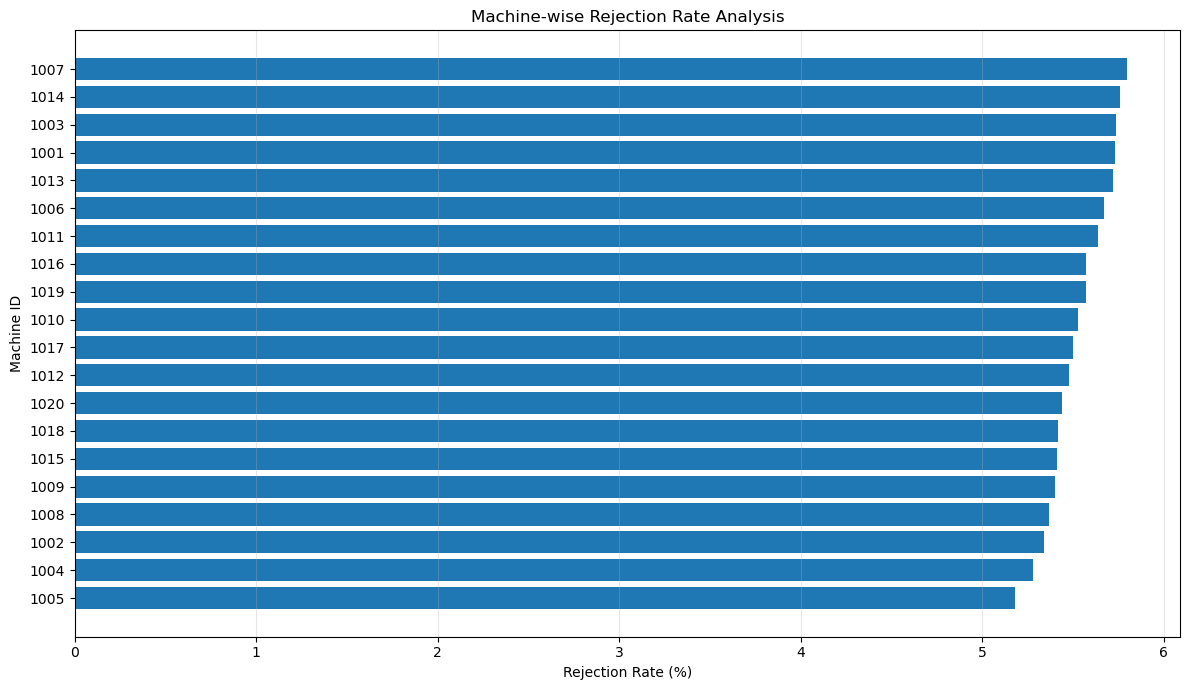

In [21]:

# Machine-wise Rejection Rate Visualization

plt.figure(figsize=(12, 7))

plt.barh(
    machine_analysis["Machine_ID"].astype(str),
    machine_analysis["Rejection_Rate"]
)

plt.title("Machine-wise Rejection Rate Analysis")
plt.xlabel("Rejection Rate (%)")
plt.ylabel("Machine ID")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [23]:

# Product-wise Quality Analysis

product_analysis = production_records.merge(
    production_orders[["Order_ID", "Product_ID"]],
    on="Order_ID",
    how="inner"
)

product_analysis = product_analysis.merge(
    products[["Product_ID", "Product_Name", "Product_Category"]],
    on="Product_ID",
    how="inner"
)

product_analysis = product_analysis.groupby(
    ["Product_ID", "Product_Name", "Product_Category"]
).agg(
    Total_Production=("Total_Units", "sum"),
    Good_Production=("Good_Units", "sum"),
    Rejected_Units=("Rejected_Units", "sum")
).reset_index()

product_analysis["Rejection_Rate"] = (
    product_analysis["Rejected_Units"] /
    product_analysis["Total_Production"] * 100
).round(2)

product_analysis = product_analysis.sort_values(
    by="Rejection_Rate",
    ascending=False
)

display(product_analysis)


,Product_ID,Product_Name,Product_Category,Total_Production,Good_Production,Rejected_Units,Rejection_Rate
5,2006,Industrial_Component_6,Automotive,42085,39681,2404,5.71
8,2009,Industrial_Component_9,Electrical,42962,40509,2453,5.71
3,2004,Industrial_Component_4,Mechanical,44645,42111,2534,5.68
4,2005,Industrial_Component_5,Mechanical,54294,51240,3054,5.62
7,2008,Industrial_Component_8,Mechanical,44300,41825,2475,5.59
6,2007,Industrial_Component_7,Automotive,48320,45642,2678,5.54
9,2010,Industrial_Component_10,Automotive,52153,49265,2888,5.54
2,2003,Industrial_Component_3,Automotive,53211,50267,2944,5.53
0,2001,Industrial_Component_1,Automotive,61054,57698,3356,5.50
11,2012,Industrial_Component_12,Electrical,56961,53829,3132,5.50


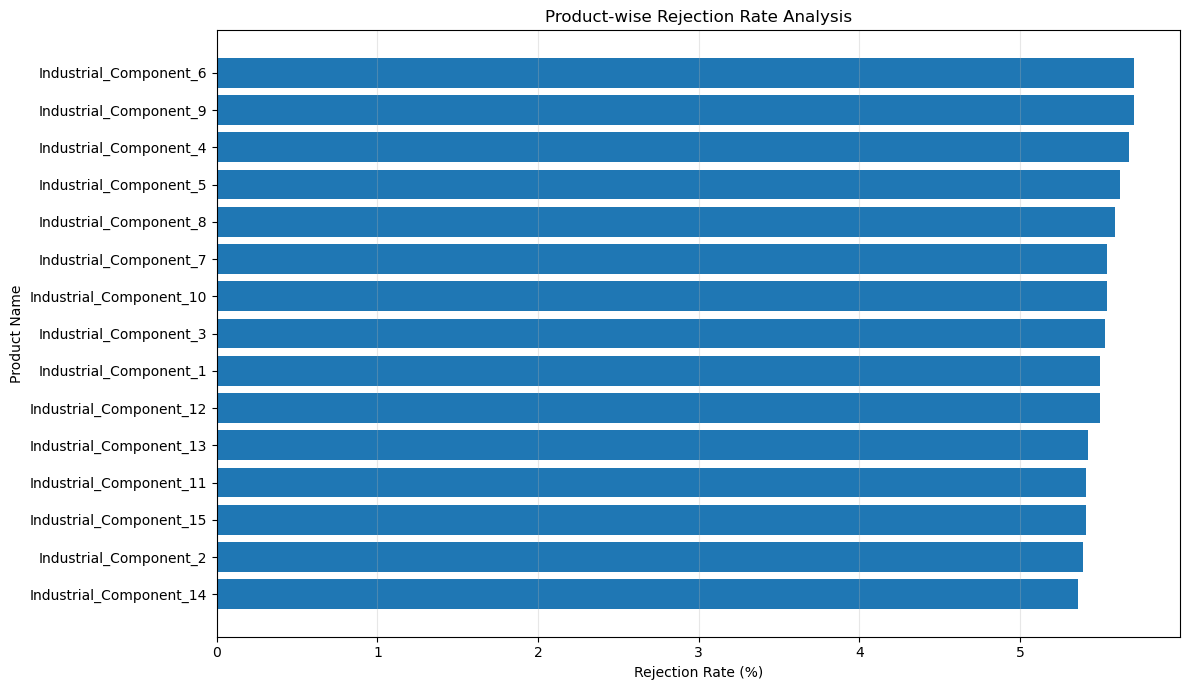

In [25]:

# Product-wise Rejection Rate Visualization

plt.figure(figsize=(12, 7))

plt.barh(
    product_analysis["Product_Name"],
    product_analysis["Rejection_Rate"]
)

plt.title("Product-wise Rejection Rate Analysis")
plt.xlabel("Rejection Rate (%)")
plt.ylabel("Product Name")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [27]:

# Machine-wise Downtime Analysis

downtime_analysis = downtime_logs.groupby("Machine_ID").agg(
    Total_Downtime=("Downtime_Minutes", "sum"),
    Downtime_Incidents=("Downtime_ID", "count"),
    Average_Downtime=("Downtime_Minutes", "mean")
).reset_index()

downtime_analysis["Average_Downtime"] = (
    downtime_analysis["Average_Downtime"].round(2)
)

downtime_analysis = downtime_analysis.sort_values(
    by="Total_Downtime",
    ascending=False
)

display(downtime_analysis)


,Machine_ID,Total_Downtime,Downtime_Incidents,Average_Downtime
4,1005,6008,62,96.90
12,1013,5815,63,92.30
9,1010,5651,59,95.78
11,1012,5547,54,102.72
6,1007,5320,50,106.40
15,1016,5143,58,88.67
7,1008,5020,50,100.40
8,1009,4884,53,92.15
13,1014,4771,51,93.55
10,1011,4581,48,95.44


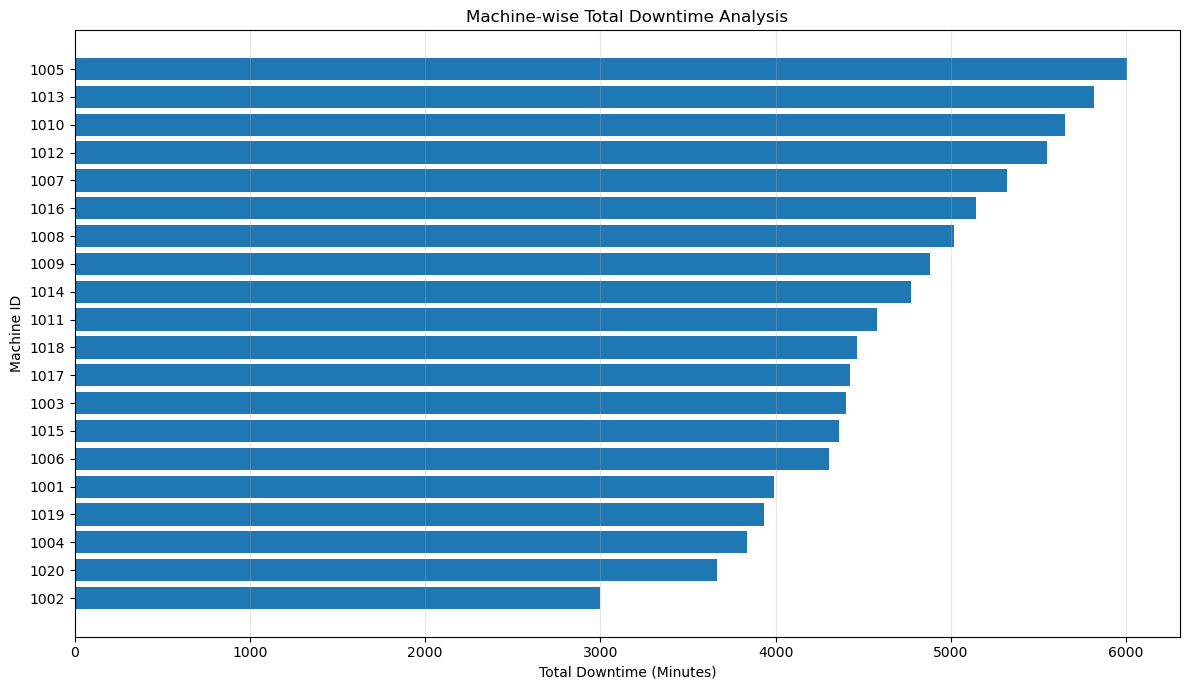

In [29]:

# Machine-wise Downtime Visualization

plt.figure(figsize=(12, 7))

plt.barh(
    downtime_analysis["Machine_ID"].astype(str),
    downtime_analysis["Total_Downtime"]
)

plt.title("Machine-wise Total Downtime Analysis")
plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Machine ID")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [31]:

# Downtime Analysis by Reason

reason_analysis = downtime_logs.groupby("Reason").agg(
    Total_Incidents=("Downtime_ID", "count"),
    Total_Downtime=("Downtime_Minutes", "sum"),
    Average_Downtime=("Downtime_Minutes", "mean")
).reset_index()

reason_analysis["Average_Downtime"] = (
    reason_analysis["Average_Downtime"].round(2)
)

reason_analysis = reason_analysis.sort_values(
    by="Total_Downtime",
    ascending=False
)

display(reason_analysis)


,Reason,Total_Incidents,Total_Downtime,Average_Downtime
5,Tool Change,175,16594,94.82
0,Machine Breakdown,172,16186,94.10
3,Preventive Maintenance,159,15859,99.74
2,Power Failure,164,15367,93.70
4,Setup Adjustment,178,15349,86.23
1,Material Shortage,152,13763,90.55


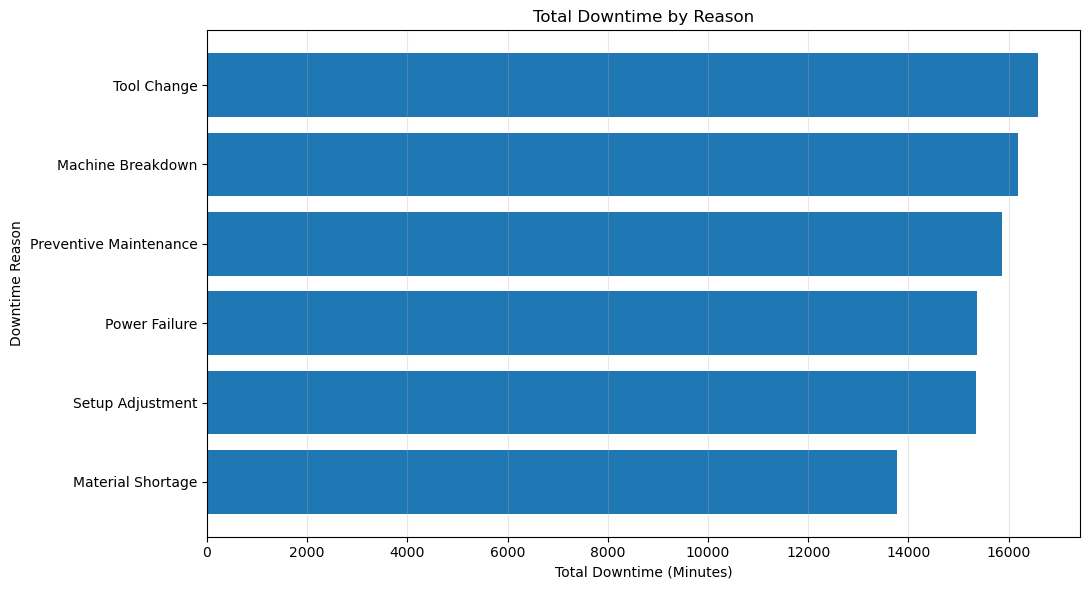

In [33]:

# Downtime by Reason Visualization

plt.figure(figsize=(11, 6))

plt.barh(
    reason_analysis["Reason"],
    reason_analysis["Total_Downtime"]
)

plt.title("Total Downtime by Reason")
plt.xlabel("Total Downtime (Minutes)")
plt.ylabel("Downtime Reason")

plt.gca().invert_yaxis()
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()


In [39]:

# Monthly Production Analysis

production_records["Production_Date"] = pd.to_datetime(
    production_records["Production_Date"]
)

monthly_analysis = production_records.groupby(
    production_records["Production_Date"].dt.month
).agg(
    Total_Production=("Total_Units", "sum"),
    Good_Production=("Good_Units", "sum"),
    Rejected_Units=("Rejected_Units", "sum")
).reset_index()

monthly_analysis.rename(
    columns={"Production_Date": "Month"},
    inplace=True
)

monthly_analysis["Rejection_Rate"] = (
    monthly_analysis["Rejected_Units"] /
    monthly_analysis["Total_Production"] * 100
).round(2)

monthly_analysis["Month_Name"] = pd.to_datetime(
    monthly_analysis["Month"],
    format="%m"
).dt.strftime("%B")

display(monthly_analysis)


,Month,Total_Production,Good_Production,Rejected_Units,Rejection_Rate,Month_Name
0,1,60196,56895,3301,5.48,January
1,2,44919,42356,2563,5.71,February
2,3,67008,63256,3752,5.60,March
3,4,62766,59397,3369,5.37,April
4,5,70251,66404,3847,5.48,May
5,6,61474,58137,3337,5.43,June
6,7,47684,45107,2577,5.40,July
7,8,63789,60211,3578,5.61,August
8,9,59665,56262,3403,5.70,September
9,10,64223,60623,3600,5.61,October


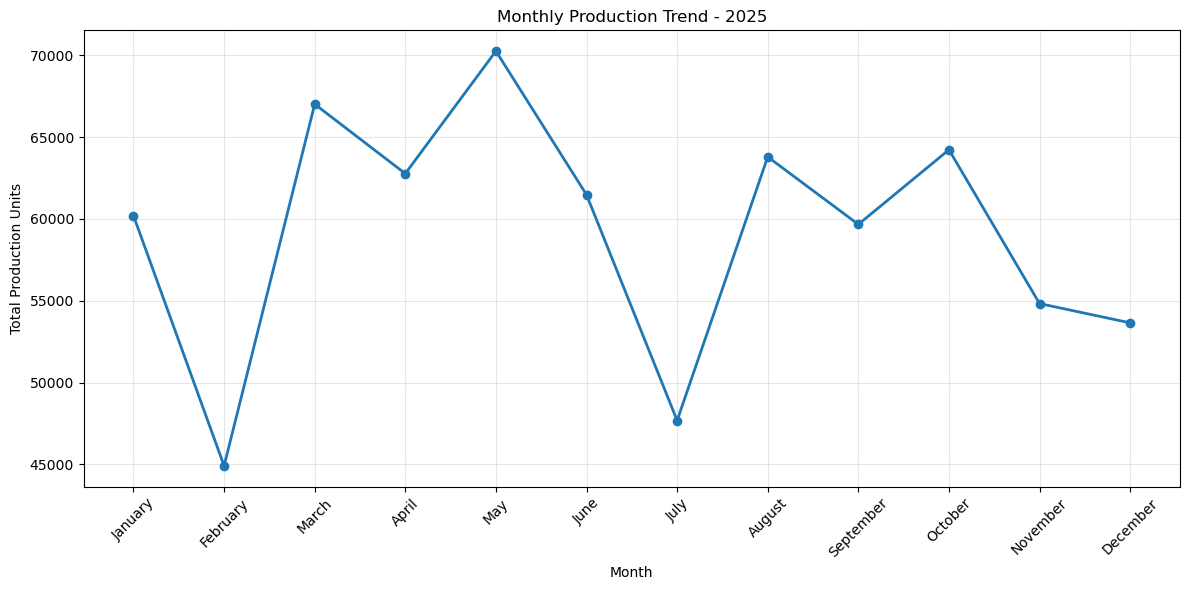

In [41]:

# Monthly Production Trend Visualization

plt.figure(figsize=(12, 6))

plt.plot(
    monthly_analysis["Month_Name"],
    monthly_analysis["Total_Production"],
    marker="o",
    linewidth=2
)

plt.title("Monthly Production Trend - 2025")
plt.xlabel("Month")
plt.ylabel("Total Production Units")

plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


In [43]:

# Product Category Analysis

category_analysis = product_analysis.groupby(
    "Product_Category"
).agg(
    Total_Production=("Total_Production", "sum"),
    Good_Production=("Good_Production", "sum"),
    Rejected_Units=("Rejected_Units", "sum")
).reset_index()

category_analysis["Rejection_Rate"] = (
    category_analysis["Rejected_Units"] /
    category_analysis["Total_Production"] * 100
).round(2)

display(category_analysis)


,Product_Category,Total_Production,Good_Production,Rejected_Units,Rejection_Rate
0,Automotive,302203,285502,16701,5.53
1,Electrical,224540,212205,12335,5.49
2,Mechanical,183711,173465,10246,5.58


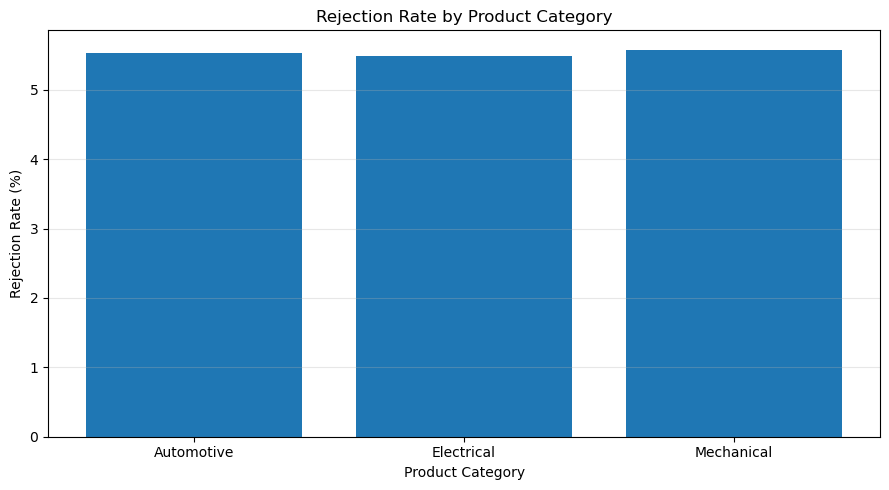

In [45]:

# Product Category Rejection Rate Visualization

plt.figure(figsize=(9, 5))

plt.bar(
    category_analysis["Product_Category"],
    category_analysis["Rejection_Rate"]
)

plt.title("Rejection Rate by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Rejection Rate (%)")

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


In [49]:

# Final Manufacturing KPI Summary

total_production = production_records["Total_Units"].sum()
good_production = production_records["Good_Units"].sum()
rejected_production = production_records["Rejected_Units"].sum()

overall_rejection_rate = (
    rejected_production / total_production * 100
)

total_downtime = downtime_logs["Downtime_Minutes"].sum()
total_downtime_hours = total_downtime / 60

total_downtime_incidents = len(downtime_logs)

highest_production_month = monthly_analysis.loc[
    monthly_analysis["Total_Production"].idxmax(),
    "Month_Name"
]

highest_rejection_machine = int(
    machine_analysis.iloc[0]["Machine_ID"]
)

highest_rejection_product = product_analysis.iloc[0]["Product_Name"]

kpi_report = pd.DataFrame({
    "Metric": [
        "Total Production",
        "Good Production",
        "Rejected Production",
        "Overall Rejection Rate",
        "Total Downtime (Minutes)",
        "Total Downtime (Hours)",
        "Total Downtime Incidents",
        "Highest Production Month",
        "Highest Rejection Machine",
        "Highest Rejection Product"
    ],
    "Value": [
        total_production,
        good_production,
        rejected_production,
        round(overall_rejection_rate, 2),
        total_downtime,
        round(total_downtime_hours, 2),
        total_downtime_incidents,
        highest_production_month,
        highest_rejection_machine,
        highest_rejection_product
    ]
})

display(kpi_report)


,Metric,Value
0,Total Production,710454
1,Good Production,671172
2,Rejected Production,39282
3,Overall Rejection Rate,5.53
4,Total Downtime (Minutes),93118
5,Total Downtime (Hours),1551.97
6,Total Downtime Incidents,1000
7,Highest Production Month,May
8,Highest Rejection Machine,1007
9,Highest Rejection Product,Industrial_Component_6


In [59]:

kpi_report.to_csv(
    "final_manufacturing_kpi_report.csv",
    index=False
)

print("KPI report saved successfully!")


KPI report saved successfully!


In [61]:
import os

print(os.getcwd())
print(os.path.exists("final_manufacturing_kpi_report.csv"))

C:\Users\chira\Downloads\Project\Manufacturing Operations Qualityc Analysis
True
